In [1]:
from codes import *

In [2]:
N = 126014024
I0 = 2
y0 = [N - I0, I0, 0, 0]

# Parameter ranges from the literature
beta_values = np.linspace(0.5534, 1.1400, 3)
gamma_values = np.linspace(0.0708, 0.2000, 3)
delta_values = np.linspace(0.0561, 0.1200, 3)

print("Beta values:", beta_values)
print("Gamma values:", gamma_values)
print("Delta values:", delta_values)


Beta values: [0.5534 0.8467 1.14  ]
Gamma values: [0.0708 0.1354 0.2   ]
Delta values: [0.0561  0.08805 0.12   ]


#### Parameter values reference: De León, U. A., Pérez, Á. G. C., Avila-Vales, E., and others (2020). "A data driven analysis and forecast of an SEIARD epidemic model for COVID-19 in Mexico." Big Data and Information Analytics, 5(1), 14-28. https://doi.org/10.3934/bdia.2020002


In [3]:
from itertools import product

# Three representative simulations: minimum, midpoint, and maximum.
# Each combination uses the same level for all three parameters.
combinaciones = [
    (beta_values[0], gamma_values[0], delta_values[0]),
    (beta_values[1], gamma_values[1], delta_values[1]),
    (beta_values[2], gamma_values[2], delta_values[2]),
]

simulations = []

for beta, gamma, delta in combinaciones:
    t, y, df = SIRD_simulation(
        beta, gamma, delta, N, y0,
        t_max=1166,
        verbose=False
    )

    peak_index = y[:, 1].argmax()
    simulations.append({
        "scenario": ["Minimum", "Midpoint", "Maximum"][len(simulations)],
        "beta": beta,
        "gamma": gamma,
        "delta": delta,
        "R0": beta / (gamma + delta),
        "infected_peak_day": t[peak_index],
        "infected_max": y[peak_index, 1],
        "deaths_final": y[-1, 3],
        "susceptible_final": y[-1, 0],
        "infected_final": y[-1, 1],
        "recovered_final": y[-1, 2],
    })

simulation_summary = pd.DataFrame(simulations)
print(f"Number of simulations: {len(simulation_summary)}")
simulation_summary


Number of simulations: 3


,scenario,beta,gamma,delta,R0,infected_peak_day,infected_max,deaths_final,susceptible_final,infected_final,recovered_final
0,Minimum,0.5534,0.0708,0.05610,4.360914,45.0,5.447580e+07,5.495384e+07,1.706665e+06,1.544410e-09,6.935351e+07
1,Midpoint,0.8467,0.1354,0.08805,3.789215,31.0,4.827952e+07,4.842183e+07,3.130912e+06,3.120853e-09,7.446128e+07
2,Maximum,1.1400,0.2000,0.12000,3.562500,23.0,4.558045e+07,4.575411e+07,4.003075e+06,3.206958e-09,7.625684e+07


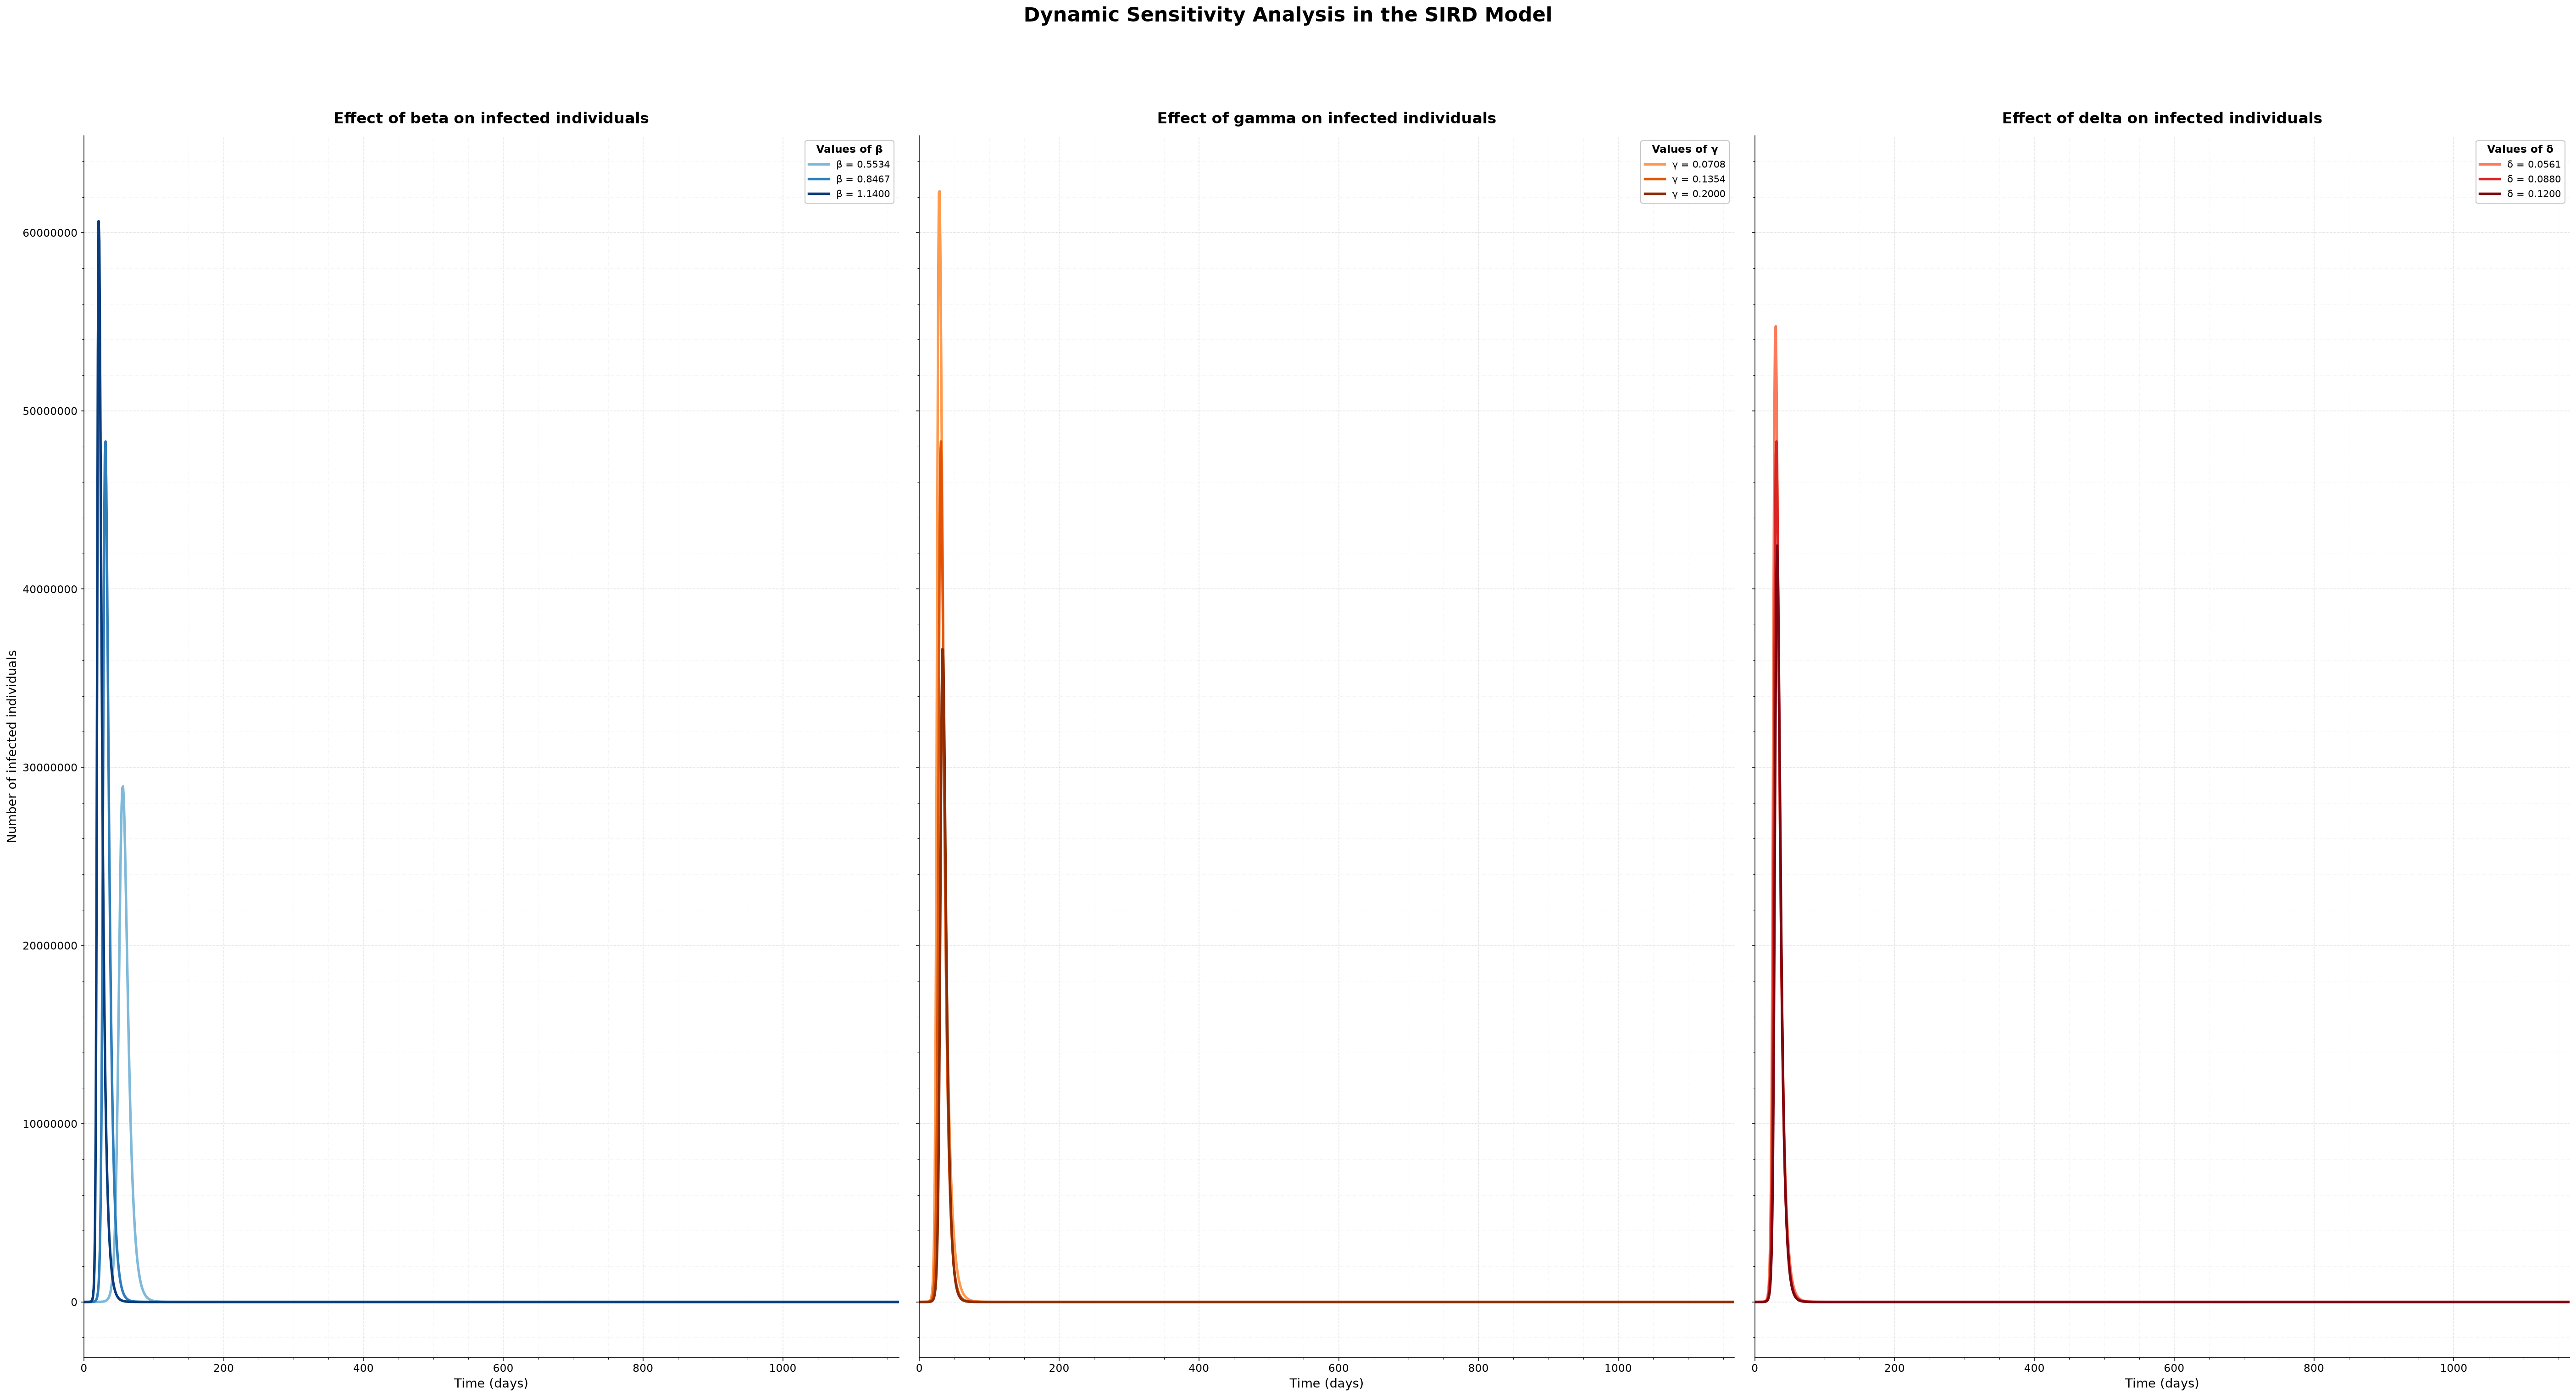

In [4]:
# Presentation-quality visual configuration
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

parametros = [
    ("beta", beta_values, "\u03b2", "Variation in beta", "Effect of beta on infected individuals", "tab:blue"),
    ("gamma", gamma_values, "\u03b3", "Variation in gamma", "Effect of gamma on infected individuals", "tab:orange"),
    ("delta", delta_values, "\u03b4", "Variation in delta", "Effect of delta on infected individuals", "tab:red"),
]

centros = {
    "beta": beta_values[len(beta_values) // 2],
    "gamma": gamma_values[len(gamma_values) // 2],
    "delta": delta_values[len(delta_values) // 2],
}

# Modify the figure size here: width, height (inches)
FIGURE_SIZE = (40, 20)
fig, axes = plt.subplots(1, 3, figsize=FIGURE_SIZE, sharey=True, constrained_layout=True)

for ax, (nombre, valores, simbolo, _titulo_corto, titulo, color) in zip(axes, parametros):
    cmap = plt.colormaps[{
        "beta": "Blues",
        "gamma": "Oranges",
        "delta": "Reds",
    }[nombre]]
    colores = cmap(np.linspace(0.45, 0.95, len(valores)))

    for valor, color_linea in zip(valores, colores):
        beta = valor if nombre == "beta" else centros["beta"]
        gamma = valor if nombre == "gamma" else centros["gamma"]
        delta = valor if nombre == "delta" else centros["delta"]

        t, y, _ = SIRD_simulation(
            beta, gamma, delta, N, y0,
            t_max=1166, verbose=False
        )

        ax.plot(
            t, y[:, 1],
            label=f"{simbolo} = {valor:.4f}",
            linewidth=2.8,
            color=color_linea,
        )

    ax.set_title(titulo, fontsize=17, pad=14)
    ax.set_xlabel("Time (days)", fontsize=14)
    ax.grid(True, which="major", linestyle="--", linewidth=0.8, alpha=0.35)
    ax.grid(True, which="minor", linestyle=":", linewidth=0.5, alpha=0.20)
    ax.minorticks_on()
    ax.set_xlim(0, 1166)
    ax.tick_params(axis="both", labelsize=12)

    legend = ax.legend(
        title=f"Values of {simbolo}",
        title_fontsize=12,
        frameon=True,
        fancybox=True,
        framealpha=0.95,
        edgecolor="0.75",
        loc="upper right",
    )
    legend.get_title().set_weight("bold")

axes[0].set_ylabel("Number of infected individuals", fontsize=14)

fig.suptitle(
    "Dynamic Sensitivity Analysis in the SIRD Model",
    fontsize=22,
    fontweight="bold",
    y=1.08,
)

# Disable scientific notation on the vertical axis
for ax in axes:
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)

plt.show()


In [5]:
# Compartment summary at day 1166 for 3 simulations
resumen_compartimentos = simulation_summary[[
    "scenario", "beta", "gamma", "delta", "R0",
    "susceptible_final", "infected_final", "recovered_final", "deaths_final"
]].copy()

resumen_compartimentos.columns = [
    "Scenario", "beta", "gamma", "delta", "R0",
    "Susceptible", "Infected", "Recovered", "Deaths"
]

print("Summary at day 1166 for 3 simulations")
print("Total population: {:,.0f}".format(N))
print("Conservation S + I + R + D = N in every simulation")

resumen_compartimentos


Summary at day 1166 for 3 simulations
Total population: 126,014,024
Conservation S + I + R + D = N in every simulation


,Scenario,beta,gamma,delta,R0,Susceptible,Infected,Recovered,Deaths
0,Minimum,0.5534,0.0708,0.05610,4.360914,1.706665e+06,1.544410e-09,6.935351e+07,5.495384e+07
1,Midpoint,0.8467,0.1354,0.08805,3.789215,3.130912e+06,3.120853e-09,7.446128e+07,4.842183e+07
2,Maximum,1.1400,0.2000,0.12000,3.562500,4.003075e+06,3.206958e-09,7.625684e+07,4.575411e+07


In [6]:
# Save results to avoid repeating the simulations
# - sird_all_results.csv: daily trajectories for 3 simulations
# - sird_compartment_summary.csv: final state of S, I, R, and D at day 1166

from pathlib import Path

ruta_resultados = Path("../Datos/sird_all_results.csv")
ruta_resumen = Path("../Datos/sird_compartment_summary.csv")

trayectorias = []

for indice, fila in enumerate(combinaciones):
    beta, gamma, delta = fila
    nombre_escenario = ["Minimum", "Midpoint", "Maximum"][indice]

    t, y, df_trayectoria = SIRD_simulation(
        beta, gamma, delta, N, y0,
        t_max=1166,
        verbose=False
    )

    trayectorias.append(pd.concat([
        pd.DataFrame({
            "scenario": nombre_escenario,
            "beta": beta,
            "gamma": gamma,
            "delta": delta,
            "day": df_trayectoria["dia"],
            "S": df_trayectoria["S"],
            "I": df_trayectoria["I"],
            "R": df_trayectoria["R"],
            "D": df_trayectoria["D"],
        })
    ], ignore_index=True))

resultados_todos = pd.concat(trayectorias, ignore_index=True)
resultados_todos.to_csv(ruta_resultados, index=False)

resumen_compartimentos.to_csv(ruta_resumen, index=False)

print(f"CSV saved: {ruta_resultados.resolve()} - {len(resultados_todos)} rows")
print(f"CSV saved: {ruta_resumen.resolve()} - {len(resumen_compartimentos)} rows")

display(resultados_todos.head())
display(resumen_compartimentos)


CSV saved: /Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/sird_all_results.csv - 3501 rows
CSV saved: /Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/sird_compartment_summary.csv - 3 rows


,scenario,beta,gamma,delta,day,S,I,R,D
0,Minimum,0.5534,0.0708,0.0561,0.0,1.260140e+08,2.000000,0.000000,0.000000
1,Minimum,0.5534,0.0708,0.0561,1.0,1.260140e+08,3.063773,0.176589,0.139924
2,Minimum,0.5534,0.0708,0.0561,2.0,1.260140e+08,4.693353,0.447103,0.354272
3,Minimum,0.5534,0.0708,0.0561,3.0,1.260140e+08,7.189683,0.861500,0.682629
4,Minimum,0.5534,0.0708,0.0561,4.0,1.260140e+08,11.013778,1.496308,1.185634


,Scenario,beta,gamma,delta,R0,Susceptible,Infected,Recovered,Deaths
0,Minimum,0.5534,0.0708,0.05610,4.360914,1.706665e+06,1.544410e-09,6.935351e+07,5.495384e+07
1,Midpoint,0.8467,0.1354,0.08805,3.789215,3.130912e+06,3.120853e-09,7.446128e+07,4.842183e+07
2,Maximum,1.1400,0.2000,0.12000,3.562500,4.003075e+06,3.206958e-09,7.625684e+07,4.575411e+07


Animation generated: sird_sensitivity_animation.gif
Approximate duration: 16.8 seconds


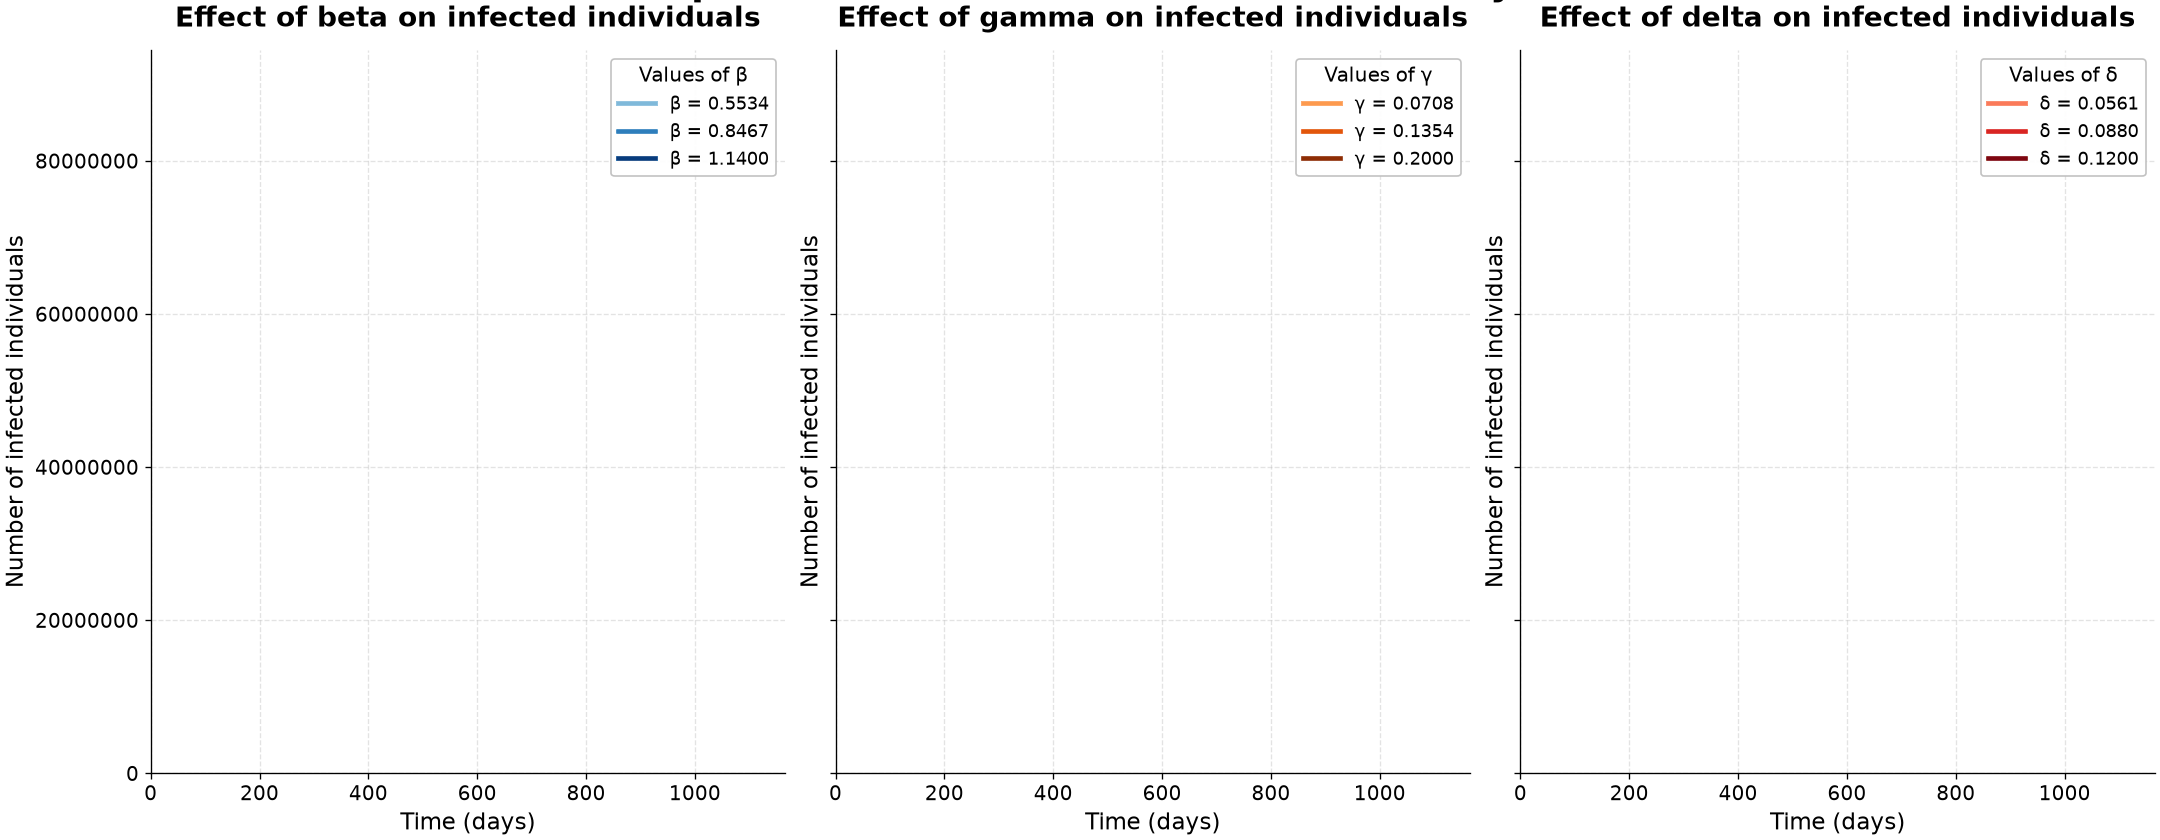

In [7]:
# Dynamic cell: generate a GIF animation of the three plots
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

# Change these values to adjust the animation
FPS_VIDEO = 12
DAYS_PER_STEP = 1
FINAL_DAY = 200
ANIMATION_FILE = "sird_sensitivity_animation.gif"

fig_anim, axes_anim = plt.subplots(1, 3, figsize=(18, 7), sharey=True, constrained_layout=True)

lineas_anim = []
curvas_anim = []

for ax, (nombre, valores, simbolo, _titulo_corto, titulo, _color) in zip(axes_anim, parametros):
    cmap = plt.colormaps[{
        "beta": "Blues",
        "gamma": "Oranges",
        "delta": "Reds",
    }[nombre]]
    colores = cmap(np.linspace(0.45, 0.95, len(valores)))
    curvas_parametro = []

    for valor, color_linea in zip(valores, colores):
        beta = valor if nombre == "beta" else centros["beta"]
        gamma = valor if nombre == "gamma" else centros["gamma"]
        delta = valor if nombre == "delta" else centros["delta"]

        t_anim, y_anim, _ = SIRD_simulation(
            beta, gamma, delta, N, y0,
            t_max=1166, verbose=False
        )
        curvas_parametro.append((t_anim, y_anim[:, 1], simbolo, valor, color_linea))

        linea, = ax.plot([], [], label=f"{simbolo} = {valor:.4f}",
                         linewidth=2.8, color=color_linea)
        lineas_anim.append(linea)

    curvas_anim.append(curvas_parametro)

    ax.set_title(titulo, fontsize=17, pad=14)
    ax.set_xlabel("Time (days)", fontsize=14)
    ax.set_ylabel("Number of infected individuals", fontsize=14)
    ax.set_xlim(0, 1166)
    ax.set_ylim(0, N * 0.75)
    ax.grid(True, linestyle="--", linewidth=0.8, alpha=0.35)
    ax.tick_params(axis="both", labelsize=12)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.legend(title=f"Values of {simbolo}", title_fontsize=12,
              frameon=True, fancybox=True, framealpha=0.95,
              edgecolor="0.75", loc="upper right")

axes_anim[0].set_ylabel("Number of infected individuals", fontsize=14)
fig_anim.suptitle("Temporal Evolution of the SIRD Model", fontsize=22,
                  fontweight="bold", y=1.04)

indices_dias = np.arange(0, FINAL_DAY + 1, DAYS_PER_STEP)


def actualizar_video(indice_dia):
    linea_global = 0
    for curvas_parametro in curvas_anim:
        for t_curva, i_curva, simbolo, valor, color in curvas_parametro:
            mascara = t_curva <= indice_dia
            lineas_anim[linea_global].set_data(t_curva[mascara], i_curva[mascara])
            linea_global += 1
    fig_anim.suptitle(
        f"Temporal Evolution of the SIRD Model - Day {indice_dia}",
        fontsize=22, fontweight="bold", y=1.04
    )
    return lineas_anim

animacion = FuncAnimation(
    fig_anim, actualizar_video, frames=indices_dias,
    interval=1000 / FPS_VIDEO, blit=False, repeat=True
)

animacion.save(ANIMATION_FILE, writer=PillowWriter(fps=FPS_VIDEO), dpi=120)
plt.close(fig_anim)

print(f"Animation generated: {ANIMATION_FILE}")
print(f"Approximate duration: {len(indices_dias) / FPS_VIDEO:.1f} seconds")
display(Image(filename=ANIMATION_FILE))
